# DecisionLab 01 — Comité d’investissement

**Janvier 2021, convention pédagogique.** Vous décidez d’expositions notionnelles à douze marchés immobiliers. Vos données sont de vrais indices Zillow Research, révisés à la date du téléchargement. Il ne s’agit ni de transactions individuelles, ni d’une reconstitution des données connues à l’époque.

**QUID** : où engager du capital sur six mois, avec quels coûts et quel risque ? Une ligne = une métropole et un mois. Indicateur = variation ZHVI à six mois, puis profit simulé. Décision = zones, allocations ou cash.

Ce kit fonctionne hors ligne après installation. Les données de révélation sont détenues séparément par l’enseignant. Ne cherchez pas les résultats historiques sur Internet pendant l’expérience.

Durée du notebook : 65 minutes guidées. **Le code de départ fonctionne sans remplir les TODO** ; ceux-ci demandent d’expliquer, choisir et comparer.

### ✅ La question métier

**Question** : où engager nos 10 M$ pour les six prochains mois, en tenant compte des frais et du risque ? Ou faut-il garder du cash ?

| | Réponse |
|---|---|
| **Qui décide ?** | Le comité d'investissement, en janvier 2021 |
| **Quelle décision ?** | Dans quelles métropoles investir, combien dans chacune, combien garder en cash |
| **Sur quoi on s'appuie ?** | Une prévision de la variation du ZHVI à six mois, pour chaque métropole |
| **Comment on juge ?** | Le profit **après frais** (achat 1 %, vente 2 %, portage 2 %/an) et le risque de perte |

**Ce qu'il faut comprendre** : une hausse prévue ne suffit pas, elle doit d'abord payer les frais. Il faut environ **+4,1 % en six mois** juste pour être à l'équilibre. Le but n'est donc pas d'avoir le meilleur modèle, mais de prendre une décision qui reste raisonnable même si le modèle se trompe. C'est la leçon de Zillow Offers.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.json").exists() and (p / "src/modeling.py").exists())
sys.path.insert(0, str(ROOT))
from src.config import load_config
from src.validation import validate_panel
from src.modeling import features, split_training, validation_scores, decision_predictions, fit_predict
from src.decisions import select_allocations, export_strategy
from src.simulation import simulate
C = load_config()
PUBLIC = ROOT / "data/processed/history_public.csv"
panel = validate_panel(pd.read_csv(PUBLIC, parse_dates=["date"]))
assert panel.date.max() <= pd.Timestamp(C["public_cutoff"])
print(panel.shape, panel.region_id.nunique(), panel.date.min(), panel.date.max())
display(panel.head())

(864, 4) 12 2015-01-31 00:00:00 2020-12-31 00:00:00


,region_id,region,date,zhvi
0,394347,"Atlanta, GA",2015-01-31,173942.955176
1,394347,"Atlanta, GA",2015-02-28,174853.818071
2,394347,"Atlanta, GA",2015-03-31,175804.313324
3,394347,"Atlanta, GA",2015-04-30,176865.134295
4,394347,"Atlanta, GA",2015-05-31,178034.638577


## 1. Explorer — 8 min
Tracer trois séries. Vérifier unités, date maximale, nombre de zones et valeurs manquantes.

**TODO** : choisir trois zones ; expliquer pourquoi l’indice ne décrit pas le prix de chaque maison. Attribution : **Data Provided by Zillow Group**.

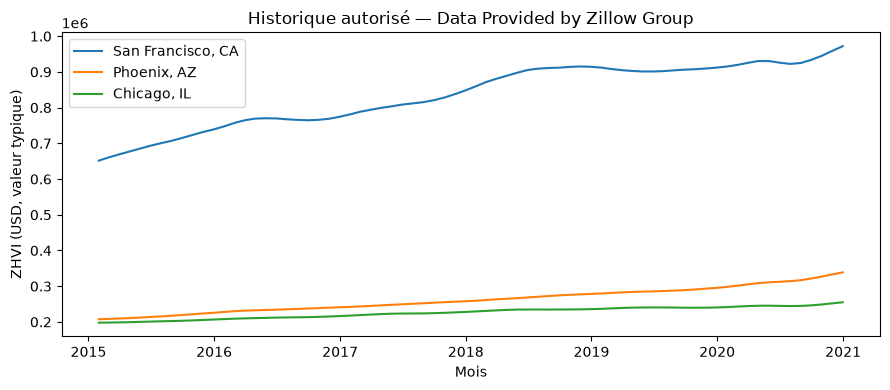

Valeurs absentes : {'region_id': 0, 'region': 0, 'date': 0, 'zhvi': 0}


In [2]:
# Trois profils contrastés : marché cher et volatil, marché en forte hausse, marché lent et stable
zones = ["San Francisco, CA", "Phoenix, AZ", "Chicago, IL"]
fig, ax = plt.subplots(figsize=(9, 4))
for name in zones:
    part = panel[panel.region.eq(name)]
    ax.plot(part.date, part.zhvi, label=name)
ax.set(xlabel="Mois", ylabel="ZHVI (USD, valeur typique)", title="Historique autorisé — Data Provided by Zillow Group")
ax.legend()
plt.tight_layout()
plt.show()
print("Valeurs absentes :", panel.isna().sum().to_dict())

In [3]:
# Résumé des 12 zones : niveau, hausse totale, 2020 par semestre, volatilité mensuelle
wide = panel.pivot(index="date", columns="region", values="zhvi")
monthly = 100 * wide.pct_change()
eda = pd.DataFrame({
    "zhvi_2015_usd": wide.iloc[0],
    "zhvi_2020_usd": wide.iloc[-1],
    "hausse_2015_2020_pct": 100 * (wide.iloc[-1] / wide.iloc[0] - 1),
    "h1_2020_pct": 100 * (wide.loc["2020-06-30"] / wide.loc["2019-12-31"] - 1),
    "h2_2020_pct": 100 * (wide.loc["2020-12-31"] / wide.loc["2020-06-30"] - 1),
    "volatilite_mensuelle_pp": monthly.std(),
    "mois_en_baisse": (monthly < 0).sum(),
}).sort_values("hausse_2015_2020_pct", ascending=False)
display(eda.round(2))

,zhvi_2015_usd,zhvi_2020_usd,hausse_2015_2020_pct,h1_2020_pct,h2_2020_pct,volatilite_mensuelle_pp,mois_en_baisse
region,,,,,,,
"Seattle, WA",328693.51,570616.64,73.60,4.67,7.34,0.50,5
"Tampa, FL",157651.87,259344.41,64.50,3.58,6.64,0.26,0
"Phoenix, AZ",207554.92,338724.55,63.20,5.77,8.42,0.32,0
"Denver, CO",290975.38,466143.65,60.20,3.04,5.38,0.37,2
"Dallas, TX",177090.53,280431.35,58.35,1.99,5.57,0.34,2
"Atlanta, GA",173942.96,274874.20,58.03,2.89,6.81,0.27,0
"Miami, FL",215676.11,325594.55,50.96,2.33,4.93,0.28,4
"San Francisco, CA",651622.86,972106.33,49.18,1.52,4.99,0.55,13
"Los Angeles, CA",504617.66,722693.73,43.22,0.41,8.47,0.87,20


### ✅ Réponses aux TODO de l'étape 1

> **TODO : choisir trois zones.**

**Choix** : San Francisco, Phoenix et Chicago. Ce sont trois profils opposés, ce qui rend la comparaison plus parlante :
- **San Francisco** : le marché le plus cher (environ 972 000 $ fin 2020) et l'un des plus instables, avec 13 mois en baisse sur 72. On voit des paliers en 2016, 2019 et mi-2020.
- **Phoenix** : +63 % depuis 2015, sans aucun mois en baisse, et +8,4 % sur le seul second semestre 2020.
- **Chicago** : la hausse la plus lente (+29 %), dans un marché moins cher et plus stable.

**Ce que montre le tableau des 12 zones** :
1. Les données sont propres : 12 métropoles, 864 lignes mensuelles de janvier 2015 à décembre 2020, aucune valeur manquante. L'unité est le dollar (valeur typique).
2. Toutes les zones montent, mais pas au même rythme : de +29 % (New York, Chicago) à +74 % (Seattle).
3. Être cher ne veut pas dire monter vite. San Francisco est la plus chère mais ne fait que +49 %, alors que Tampa, la moins chère, fait +65 %.
4. Le risque varie selon les zones. Los Angeles (20 mois en baisse) et San Francisco sont les plus volatiles. Phoenix, Tampa et Atlanta n'ont jamais baissé.
5. **Point clé** : toutes les zones accélèrent au second semestre 2020, de +3 % à +8,5 % en six mois. Un modèle qui prolonge la tendance risque donc d'être trop optimiste. C'est une opportunité, mais aussi un risque de retournement.

**Attention à l'échelle du graphique** : en dollars, Phoenix paraît presque plate à côté de San Francisco, alors qu'elle a davantage monté en pourcentage. C'est pour cela qu'on compare des variations en %, pas des prix en dollars.

> **TODO : expliquer pourquoi l'indice ne décrit pas le prix de chaque maison.**

Le ZHVI est une valeur *typique estimée* pour une métropole entière. Il lisse les écarts entre quartiers, tailles et états des logements, donc une maison précise peut évoluer très différemment de l'indice. Il ne contient pas non plus :
- les frais de rénovation ;
- le délai de revente ;
- la négociation à l'achat et à la vente.

Enfin, la série a été **révisée** depuis 2021 : ce ne sont pas exactement les chiffres qu'on connaissait à l'époque.

*Data Provided by Zillow Group.*

## 2. Définir la cible et purger le train — 10 min

`target_pp = 100 × (ZHVI[t+6] / ZHVI[t] − 1)`. Une erreur de 2 signifie **2 points de pourcentage**, pas 2 dollars. Les entrées sont les variations passées à 1, 3, 6 et 12 mois.

Le train ne contient que des cibles entièrement réalisées **avant la première date de validation**. Les dernières lignes sans cible sont conservées pour la décision, jamais utilisées comme labels.

Convention de disponibilité : un mois de délai de publication, non vérifié pour chaque ancienne livraison. Même avec la purge, la série actuelle a été révisée ; ce n’est pas un backtest en données réellement archivées.

**TODO** : expliquer le risque d’un split aléatoire et lire les bornes affichées.

In [4]:
table = features(panel, C["horizon_months"])
train, valid = split_training(table, C)
assert train.target_end.max() < valid.date.min()
print("TRAIN", train.date.min(), train.date.max(), "fin des labels :", train.target_end.max())
print("VALIDATION", valid.date.min(), valid.date.max(), "fin des labels :", valid.target_end.max())
print("Effectifs", len(train), len(valid))
display(table[["region", "date", "return_6m_pp", "target_pp", "target_end"]].head(16))

TRAIN 2016-01-31 00:00:00 2018-06-30 00:00:00 fin des labels : 2018-12-31 00:00:00
VALIDATION 2019-01-31 00:00:00 2019-12-31 00:00:00 fin des labels : 2020-06-30 00:00:00
Effectifs 360 144


,region,date,return_6m_pp,target_pp,target_end
0,"Atlanta, GA",2015-01-31,NaN,3.724157,2015-07-31
1,"Atlanta, GA",2015-02-28,NaN,3.900665,2015-08-31
2,"Atlanta, GA",2015-03-31,NaN,4.102620,2015-09-30
3,"Atlanta, GA",2015-04-30,NaN,4.203907,2015-10-31
4,"Atlanta, GA",2015-05-31,NaN,4.223333,2015-11-30
5,"Atlanta, GA",2015-06-30,NaN,4.304432,2015-12-31
6,"Atlanta, GA",2015-07-31,3.724157,4.415817,2016-01-31
7,"Atlanta, GA",2015-08-31,3.900665,4.528959,2016-02-29
8,"Atlanta, GA",2015-09-30,4.102620,4.427097,2016-03-31
9,"Atlanta, GA",2015-10-31,4.203907,4.374915,2016-04-30


### ✅ Réponses aux TODO de l'étape 2

> **TODO : lire les bornes affichées.**

- **Cible** : hausse du ZHVI sur six mois, en points de % (exemple : Atlanta, janvier 2015 → +3,72 %).
- **Train** : origines de janvier 2016 à juin 2018, soit **360 lignes** (12 zones × 30 mois). Il commence en 2016 parce que la variable « variation sur 12 mois » a besoin d'un an d'historique. Le dernier label se termine en **décembre 2018**, juste avant la validation.
- **Validation** : toute l'année **2019**, soit **144 lignes** (12 zones × 12 mois). Ses labels se terminent en juin 2020.
- **Purge** : les origines de juillet à décembre 2018 sont retirées, parce que leurs cibles débordent sur 2019. Les garder ferait fuiter de l'information de la validation dans le train.
- **Décision** : les mois de fin 2020 n'ont pas de cible, puisque le futur est inconnu. Ils servent uniquement à décider.

> **TODO : expliquer le risque d'un split aléatoire.**

Les lignes se chevauchent dans le temps. Le tableau ci-dessus le montre : pour Atlanta, la **cible de janvier 2015 (3,724)** est exactement la **variation passée à six mois de juillet 2015 (3,724)**. La réponse d'une ligne sert donc d'indice à une autre.

Avec un split aléatoire, le modèle apprendrait sur juillet et serait testé sur janvier : il aurait déjà vu la réponse. Ses scores seraient trop beaux et la décision serait fausse. C'est pour cela qu'on découpe dans l'ordre chronologique, avec une purge.

## 3. Baselines et régression — 12 min

Comparer « variation nulle », « dernière variation à six mois » et régression linéaire. Le prétraitement est appris uniquement sur le train.

**TODO** : choisir une méthode sur la validation ; justifier en MAE, RMSE et biais. Aucun score de test futur n’est fourni ici.

In [5]:
scores = validation_scores(table, C)
display(scores.round(3))
MODEL = "linear"  # Choix : plus petite MAE et RMSE en validation 2019 (voir réponse ci-dessous)
predictions = decision_predictions(panel, MODEL, C)
display(predictions.round(3))

,model,observations,mae_pp,rmse_pp,bias_pp
0,zero,144,2.237,2.617,-2.140
1,momentum,144,1.717,2.264,-0.757
2,linear,144,1.276,1.566,0.719


C:\Users\Mouss\AppData\Local\Temp\ipykernel_21740\2872965473.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predictions.round(3))


,region_id,region,date,zhvi,predicted_return_pp
0,394347,"Atlanta, GA",2020-12-31,274874.204,4.047
1,394404,"Boston, MA",2020-12-31,537209.556,3.649
2,394463,"Chicago, IL",2020-12-31,254993.343,2.923
3,394514,"Dallas, TX",2020-12-31,280431.352,3.570
4,394530,"Denver, CO",2020-12-31,466143.645,3.166
5,394856,"Miami, FL",2020-12-31,325594.553,3.544
6,394913,"New York, NY",2020-12-31,529334.502,3.496
7,394976,"Phoenix, AZ",2020-12-31,338724.550,4.525
8,395057,"San Francisco, CA",2020-12-31,972106.334,3.002
9,395078,"Seattle, WA",2020-12-31,570616.640,3.719


### ✅ Réponses aux TODO de l'étape 3

> **TODO : choisir une méthode sur la validation et la justifier en MAE, RMSE et biais.**

| Modèle | Idée | MAE (pp) | RMSE (pp) | Biais (pp) |
|---|---|---|---|---|
| zero | « le prix ne bouge pas » | 2,24 | 2,62 | −2,14 |
| momentum | « les six prochains mois refont les six derniers » | 1,72 | 2,26 | −0,76 |
| **linear** | régression sur les variations à 1, 3, 6 et 12 mois | **1,28** | **1,57** | **+0,72** |

**Comment lire ces scores** :
- la **MAE** est l'erreur moyenne : la régression se trompe d'environ **1,3 point** ;
- la **RMSE** punit davantage les grosses erreurs : celle de la régression est la plus faible, donc elle fait moins de grosses erreurs ;
- le **biais** indique le sens de l'erreur. Positif, le modèle est trop optimiste ; négatif, il est trop pessimiste.

**Choix : la régression linéaire.** Elle bat les deux baselines sur la MAE et sur la RMSE.

**Limite** : son biais est de **+0,72 pp**, elle est un peu trop optimiste. En 2019, le marché a ralenti (+2,1 % en moyenne, contre +3,8 % sur la période du train) et le modèle ne l'a pas anticipé. Il faudra en tenir compte dans la marge de sécurité.

**Prévisions pour le premier semestre 2021** : Phoenix +4,53 %, Tampa +4,21 %, Atlanta +4,05 %, puis les autres zones entre +2,92 % (Chicago) et +3,72 % (Seattle). Le modèle momentum aurait prévu jusqu'à +8,5 %, parce qu'il recopie l'accélération de fin 2020. C'est le piège repéré dans l'EDA.

*Le message en rouge (`UserWarning`) est un simple avertissement : pandas ne peut pas arrondir la colonne date. Il n'a aucun effet sur les résultats.*

## 4. Passer de la prévision à la décision — 15 min

Hypothèses **simulées**, communes à la séance : budget, frais d’achat, frais de vente, portage, limite par zone et cash minimal. La marge de sécurité est un seuil de sélection, **pas un coût ajouté au profit**.

Le code choisit des zones uniquement si leur rendement net prévu dépasse la marge. Il peut ne rien acheter. Les coûts de rénovation et les financements propres à Zillow ne sont pas reconstitués.

**TODO** : tester une marge différente sur la validation, puis fixer la vôtre. Comparer aussi à conserver du cash. Les contraintes communes ne changent pas entre groupes.

In [6]:
economics = dict(C["economics"])
economics["safety_margin_pp"] = 0.25  # Choix : marge de 0,25 pp (comparaison des marges ci-dessous)
TOP_N = 5
# Validation économique sur douze cohortes mensuelles séparées, budget réinitialisé par cohorte.
# Ces cohortes se chevauchent : ce n’est PAS un portefeuille cumulé ni 12 expériences indépendantes.
validation_economics = []
for origin, cohort in valid.groupby("date"):
    cohort = cohort.copy()
    cohort["predicted_return_pp"] = fit_predict(train, cohort, MODEL, C["horizon_months"])
    positions = select_allocations(cohort, economics, C["horizon_months"], TOP_N)
    actual = cohort[["region_id", "target_pp"]].rename(columns={"target_pp": "actual_return_pp"})
    result, _ = simulate(positions, actual, economics, C["horizon_months"])
    validation_economics.append({"origin": origin, **result})
validation_economics = pd.DataFrame(validation_economics)
display(validation_economics[["origin", "capital_engaged_usd", "profit_usd", "return_on_budget_pct"]].round(2))
allocations = select_allocations(predictions, economics, C["horizon_months"], TOP_N)
display(pd.DataFrame(allocations, columns=["region_id", "capital_usd"]))
print("Cash volontaire possible. Aucune réalisation future consultée.")

C:\Users\Mouss\AppData\Local\Temp\ipykernel_21740\1203687495.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(validation_economics[["origin", "capital_engaged_usd", "profit_usd", "return_on_budget_pct"]].round(2))


,origin,capital_engaged_usd,profit_usd,return_on_budget_pct
0,2019-01-31,0.0,0.00,0.00
1,2019-02-28,0.0,0.00,0.00
2,2019-03-31,0.0,0.00,0.00
3,2019-04-30,2000000.0,-38105.38,-0.38
4,2019-05-31,2000000.0,-11672.40,-0.12
5,2019-06-30,0.0,0.00,0.00
6,2019-07-31,0.0,0.00,0.00
7,2019-08-31,0.0,0.00,0.00
8,2019-09-30,0.0,0.00,0.00
9,2019-10-31,0.0,0.00,0.00


,region_id,capital_usd
0,394976,2000000.0


Cash volontaire possible. Aucune réalisation future consultée.


In [7]:
# Comparaison des marges sur les 12 cohortes de validation (mêmes hypothèses communes, seule la marge change)
comparison = []
for margin in [0.0, 0.25, 0.5, 1.0, 1.3]:
    test = dict(economics, safety_margin_pp=margin)
    profits, engaged = [], []
    for origin, cohort in valid.groupby("date"):
        cohort = cohort.copy()
        cohort["predicted_return_pp"] = fit_predict(train, cohort, MODEL, C["horizon_months"])
        positions = select_allocations(cohort, test, C["horizon_months"], TOP_N)
        actual = cohort[["region_id", "target_pp"]].rename(columns={"target_pp": "actual_return_pp"})
        result, _ = simulate(positions, actual, test, C["horizon_months"])
        profits.append(result["profit_usd"])
        engaged.append(result["capital_engaged_usd"])
    decision = select_allocations(predictions, test, C["horizon_months"], TOP_N)
    comparison.append({"marge_pp": margin,
                       "cohortes_investies": sum(e > 0 for e in engaged),
                       "cohortes_en_perte": sum(p < 0 for p in profits),
                       "profit_moyen_usd": np.mean(profits),
                       "pire_cohorte_usd": min(profits),
                       "zones_2021": " ; ".join(panel.set_index("region_id").region.drop_duplicates()[[a["region_id"] for a in decision]]) or "aucune (cash)",
                       "capital_2021_usd": sum(a["capital_usd"] for a in decision)})
display(pd.DataFrame(comparison).round({"profit_moyen_usd": 0, "pire_cohorte_usd": 0}))
print("Référence « tout en cash » : profit 0 $ sur chaque cohorte (cash_annual_rate = 0).")

,marge_pp,cohortes_investies,cohortes_en_perte,profit_moyen_usd,pire_cohorte_usd,zones_2021,capital_2021_usd
0,0.00,5,5,-17899.0,-65902.0,"Phoenix, AZ ; Tampa, FL",4000000.0
1,0.25,2,2,-4148.0,-38105.0,"Phoenix, AZ",2000000.0
2,0.50,2,2,-4148.0,-38105.0,aucune (cash),0.0
3,1.00,0,0,0.0,0.0,aucune (cash),0.0
4,1.30,0,0,0.0,0.0,aucune (cash),0.0


Référence « tout en cash » : profit 0 $ sur chaque cohorte (cash_annual_rate = 0).


### ✅ Réponses aux TODO de l'étape 4

> **TODO : tester une marge différente sur la validation.**

La règle n'investit dans une zone que si le **gain net prévu** (hausse prévue moins frais d'achat, de vente et de portage) dépasse la marge. Le tableau ci-dessus teste cinq marges, sans rien changer d'autre :

| Marge | Cohortes 2019 investies | Résultat | Décision 2021 |
|---|---|---|---|
| 0 | 5 / 12 | les 5 en perte (pire : −66 000 $) | Phoenix + Tampa, 4 M$ |
| **0,25** | **2 / 12** | **2 pertes (−38 000 $ et −12 000 $, soit −0,4 % et −0,1 % du budget)** | **Phoenix, 2 M$** |
| 0,5 | 2 / 12 | 2 pertes | aucune (cash) |
| 1,0 et 1,3 | 0 / 12 | 0 $ | aucune (cash) |

**Ce qu'on en tire** : plus la marge est haute, moins on investit. En 2019, chaque fois que le modèle a investi, la cohorte a fini en légère perte, ce qui confirme son biais optimiste.

> **TODO : fixer votre marge.**

**Choix : 0,25 pp.** Ce choix investit **2 M$ dans Phoenix** et garde **7,98 M$ en cash** (2 M$ investis + 20 000 $ de frais d'achat).

Pourquoi ce choix :
- Phoenix est la seule zone dont le gain net prévu (**+0,43 pp**) dépasse la marge. Le gain attendu est d'environ **8 700 $**.
- L'exposition est limitée : une seule zone, au plafond de 20 % du budget. 80 % du budget reste en cash.
- En validation, les pertes avec cette marge sont restées faibles (au pire −0,4 % du budget).

**Limite honnête** : l'avantage prévu (0,43 pp) est **plus petit que l'erreur moyenne du modèle (1,3 pp)**. Cette position est donc un pari mesuré, pas une certitude.

> **TODO : comparer à conserver du cash.**

Tout garder en cash rapporte **0 $** (taux du cash = 0 %) mais ne fait jamais perdre. Notre choix accepte un petit risque, limité à 20 % du budget, pour un gain attendu modeste. Si Phoenix monte moins d'environ 4,1 % en six mois, la position perd de l'argent. Les contraintes communes (frais, plafond par zone, cash minimal) n'ont pas été modifiées.

## 5. Geler la stratégie — 8 min

Changer `TEAM` pour votre groupe, vérifier les positions, puis exécuter l’export **une seule fois**. Les fichiers existants ne sont pas remplacés. Remettre le JSON et son empreinte à l’enseignant avant révélation.

**TODO** : dans un fichier `pitch.txt`, écrire la méthode, le motif de la marge et du niveau de cash, un risque et un signal d’arrêt.

L’empreinte détecte les modifications ; seule la collecte externe par l’enseignant établit l’engagement avant révélation.

In [8]:
TEAM = "Groupe_1"
path, sha256 = export_strategy(TEAM, MODEL, allocations, economics, PUBLIC, ROOT / "submissions", C)
print("Fichier à remettre :", path)
print("SHA256 :", sha256)

Fichier à remettre : C:\Users\Mouss\OneDrive\Desktop\Action\ai-course-student\usecase\DecisionLab_01_Zillow_Etudiant\submissions\Groupe_1.json
SHA256 : 56184f075908aebafb0723d8a20b32d3ed2987ccbe5bcb68cceb1e01e6a21f39


### ✅ Réponses aux TODO de l'étape 5

> **TODO : changer `TEAM`, vérifier les positions et exporter une seule fois.**

- `TEAM = "Groupe_1"` ; positions vérifiées : **Phoenix, 2 000 000 $**.
- L'export crée `submissions/Groupe_1.json` et affiche son **SHA256** ci-dessus. Il faut remettre les deux au professeur **avant la révélation**.
- Le SHA256 est l'empreinte du fichier. Si une seule lettre change, l'empreinte change. Comme le professeur garde une copie, c'est la preuve que la décision a été prise avant de connaître le résultat.
- Ne pas relancer cette cellule : le fichier existe déjà, et une seconde exécution s'arrête volontairement avec `FileExistsError`.

> **TODO : écrire `pitch.txt` (méthode, motif de la marge et du cash, un risque, un signal d'arrêt).**

Le fichier est prêt : `submissions/pitch.txt`. Résumé :
- **Méthode** : régression linéaire. MAE 1,28 pp, RMSE 1,57 pp, biais +0,72 pp en validation 2019.
- **Marge et cash** : marge de 0,25 pp ; 2 M$ dans Phoenix, 7,98 M$ en cash. Une seule zone passe le seuil, et le biais optimiste du modèle justifie de rester très majoritairement en cash.
- **Risque** : l'accélération de fin 2020 peut s'inverser. L'indice ne voit ni les travaux, ni le délai de revente.
- **Signal d'arrêt** : deux mois consécutifs de baisse du ZHVI de Phoenix, ou une hausse inférieure à 2 % après trois mois.

## 6. Préparer le conseil d’administration — 12 min

Sans consulter de futur, préparer un pitch de deux minutes :
1. Quelle méthode et quelle erreur de validation ?
2. Combien investir et pourquoi garder du cash ?
3. Quel risque les indices ne représentent-ils pas ?
4. Qu’est-ce qui pourrait invalider votre décision ?

L’enseignant révélera ensuite les indices futurs et fera tourner le moteur privé. Vous interpréterez le profit, les pertes, l’exposition, les scénarios de stress et la différence avec les stratégies naïves. Une bonne MAE ne garantit ni profit ni robustesse.

### ✅ Préparation du pitch (2 minutes)

**1. Quelle méthode et quelle erreur de validation ?**
Une régression linéaire sur les variations passées à 1, 3, 6 et 12 mois. Elle se trompe d'environ 1,3 point en moyenne (MAE 1,28 pp, RMSE 1,57 pp), ce qui bat les baselines « zéro » (2,24) et « momentum » (1,72). Elle est cependant un peu trop optimiste (biais +0,72 pp).

**2. Combien investir et pourquoi garder du cash ?**
2 M$ dans Phoenix (20 % du budget) et 7,98 M$ en cash. Phoenix est la seule zone dont la hausse prévue (+4,5 %) dépasse les frais (environ 4,1 %) et la marge. Comme cet avantage est inférieur à l'erreur du modèle et qu'en 2019 chaque investissement a fini en légère perte, on reste à 80 % en cash.

**3. Quel risque les indices ne représentent-ils pas ?**
Le ZHVI est une moyenne de métropole. Il ne montre ni le prix d'une maison précise, ni les travaux, ni le délai de revente, ni la négociation, ni la liquidité. Les données ont aussi été révisées après coup.

**4. Qu'est-ce qui pourrait invalider notre décision ?**
- Un retournement après l'accélération de 2020 (le scénario de stress du cours retient −8 % à la sortie).
- Des frais plus élevés que prévu.
- Le fait que la validation ne porte que sur une seule année (2019). Un résultat sur une période unique ne prouve pas la robustesse.

**Pistes pour améliorer le modèle** :
- une **validation glissante** sur plusieurs années, plutôt que sur 2019 seulement ;
- **plus de variables** : volatilité récente, saisonnalité (mois de l'année), accélération (variation à 3 mois comparée à celle à 12 mois) ;
- un **modèle régularisé** (Ridge), plus stable avec peu de données ;
- une **fourchette de prévision** plutôt qu'un seul chiffre, pour n'investir que si le scénario prudent couvre aussi les frais ;
- **corriger le biais optimiste** mesuré en validation, ou fixer la marge à partir de la MAE.